In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Markov Chain

In this task you will implement missing method `run` for the `MarkovChain` class. This class represents a generic Markov chain with an initial state `0` and a transition matrix `_matrix` defining transition probabilities between states (i.e. $P(X_{t+1}=j | X_t=i) = \text{matrix}[i, j]$). Method `run` should simulate the Markov chain for a given number of steps and return the sequence of visited states, including the initial state. Thus, `run(steps)` returns `steps + 1` states, and `run(0, initial_state=i)` returns `[i]`. Assume the transition matrix is a nonempty square matrix of nonnegative probabilities whose rows sum to one.

**Algorithm (Monte Carlo):**

1. Choose an initial state $X_0$, or `initial_state`.

2. For $t = 0,1,\dots,$`steps-1`:

   a. Let $i = X_t$ be the current state.

   b. Draw $U \sim \mathrm{Uniform}(0,1)$, with $0 \le U < 1$.

   c. Move to the unique $j$ such that $U \in \big[\sum_{k < j} \text{matrix}[i, k],\, \sum_{k \le j} \text{matrix}[i, k]\big)$.

*Hint:* instead of doing the cumulative-sum selection by hand (2c), you can also use [`numpy.random.choice`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.choice.html) to sample the next state from row $i$ of the transition matrix.

In [ ]:
from typing import List


class MarkovChain:
    def __init__(self, matrix: List[List[float]]):
        self._matrix = matrix

    def run(self, steps: int, initial_state: int = 0) -> List[int]:
        # Your code here.
        raise NotImplementedError("Complete this exercise.")


# Make the sampling checks reproducible when this cell is rerun.
np.random.seed(42)

chain = MarkovChain([[1.0]])
assert chain.run(5) == [0, 0, 0, 0, 0, 0]

chain = MarkovChain([[0.0, 1.0], [1.0, 0.0]])
assert chain.run(6) == [0, 1, 0, 1, 0, 1, 0]
assert chain.run(0, initial_state=1) == [1]
assert chain.run(3, initial_state=1) == [1, 0, 1, 0]

chain = MarkovChain([[0.0, 0.1, 0.9], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
count_1, count_2 = 0, 0
for _ in range(1000):
    result = chain.run(2)
    if result[1] == 1:
        count_1 += 1
    else:
        count_2 += 1
assert 60 < count_1 < 140
assert 860 < count_2 < 940

chain = MarkovChain([[0.5, 0.5], [0.5, 0.5]])
count_0, count_1 = 0, 0
for _ in range(1000):
    result = chain.run(10)
    if result[-1] == 0:
        count_0 += 1
    else:
        count_1 += 1
assert 400 < count_0 < 600
assert 400 < count_1 < 600

print("Markov-chain checks passed.")


# Guess the Chain

In this task you will be given a black-box Markov chain represented by the `MarkovChain` class. Your goal is to estimate its transition matrix by running the chain multiple times and collecting statistics.

*Hint:* you can do it with the Monte Carlo method. When you run the chain and see $x_t = i$ and $x_{t + 1} = j$ this is basically a sample from the distribution $P(X_{t + 1} | X_t = i)$, so you can use a number of such samples to estimate the probabilities.

Use only `chain.run(...)`, without inspecting `chain._matrix`. Here `runs` is the total number of runs and `steps_per_run` is the number of transitions in each run. Distribute the starting states across all `state_count` states: a state may be unreachable from state 0. Assume `runs >= state_count >= 1` and `steps_per_run >= 1`, so every state can be sampled as a source at least once. Normalize the transition counts separately for each source state.


In [ ]:
def guess_transition_matrix(
    chain: MarkovChain,
    state_count: int,
    runs: int,
    steps_per_run: int
) -> List[List[float]]:
    # Your code here.
    raise NotImplementedError("Complete this exercise.")


def check_matrices_equal(
    mat1: List[List[float]],
    mat2: List[List[float]],
    tol: float = 3e-2
) -> bool:
    try:
        left = np.asarray(mat1, dtype=float)
        right = np.asarray(mat2, dtype=float)
    except (TypeError, ValueError):
        return False
    return bool(
        left.ndim == right.ndim == 2
        and left.shape == right.shape
        and np.isfinite(left).all()
        and np.isfinite(right).all()
        and np.allclose(left, right, atol=tol, rtol=0)
    )


MATRICES = [
    [[1.0]],
    [[1.0, 0.0], [0.25, 0.75]],  # State 1 is unreachable from state 0.
    [[0.0, 1.0], [1.0, 0.0]],
    [[0.0, 0.1, 0.9], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]],
    [[0.5, 0.5], [0.5, 0.5]],
    [[0.3, 0.5, 0.2], [0.1, 0.6, 0.3], [0.4, 0.4, 0.2]],
    [[0.2, 0.2, 0.6], [0.3, 0.4, 0.3], [0.5, 0.3, 0.2]],
]

np.random.seed(42)
for matrix in MATRICES:
    chain = MarkovChain(matrix)
    guessed_matrix = guess_transition_matrix(chain, len(matrix), runs=10000, steps_per_run=10)
    assert check_matrices_equal(matrix, guessed_matrix), f"Failed for matrix: {matrix}"
print("Transition-matrix estimation checks passed.")


# 2. Hidden Markov Model (HMM)

In the next problem you will play with the occasionally dishonest casino. The occasionally dishonest casino has two type of dice: fair and biased (or loaded). The fair die has equal probabilities for all faces, while the biased one has higher probability for rolling 6 rather than other faces. You do not know which die is used at each step, but you can observe the outcomes of the rolls. After each roll, there is a probability that the casino will switch to the other die.

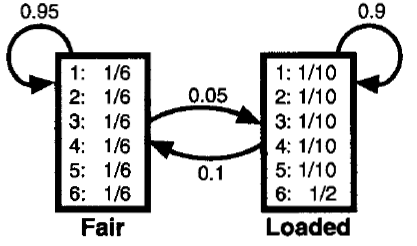

In [ ]:
from dataclasses import dataclass


@dataclass
class HiddenMarkovModel:
    # Number of (hidden) states.
    # States are numbered from 0 to state_count - 1.
    state_count: int
    # Number of possible observations.
    # Observations are numbered from 0 to observation_count - 1.
    observation_count: int

    # i-th element is the probability of starting in state i.
    start_probability: List[float]
    # Element (i, j) is the probability of going into state j from state i.
    # Formally, this is P(X_{t + 1} = j | X_t = i).
    transition_probability: List[List[float]]
    # Element (i, j) is the probability of the emission of the
    # observation j in the state i.
    # Formally, this is P(Y_t = j | X_t = i).
    emission_probability: List[List[float]]


casino = HiddenMarkovModel(
    # States are 0: Fair die, 1: Loaded die.
    state_count=2,
    # Die faces 1 to 6 are encoded as observations 0 to 5.
    observation_count=6,
    # High probability of starting with the fair die.
    start_probability=[0.9, 0.1],
    # High probability of staying with the same die.
    transition_probability=[
        [0.95, 0.05],
        [0.10, 0.90],
    ],
    # Fair die is uniform, loaded die favors 6.
    emission_probability=[
        [1/6, 1/6, 1/6, 1/6, 1/6, 1/6],  # Fair die
        [0.1, 0.1, 0.1, 0.1, 0.1, 0.5],  # Loaded die
    ],
)

# Casino: Viterbi Score

In this problem you will implement the Viterbi algorithm to find the most likely sequence of hidden states (i.e., which die was used at each step) given the observed sequence of rolls. You will compute its log joint probability with the observations, without reconstructing the sequence itself.

Let's formally define our Hidden Markov Model (HMM). HMM consists of:
* A set of $n$ hidden states (in our case, $n = 2$ corresponding to fair and biased dice). States are indexed from `0` to `n - 1` where `n` is defined in `state_count` field of `HiddenMarkovModel` class.
* A set of observations (in our case, possible outcomes of dice rolls, i.e., numbers from `1` to `6`). Observations are indexed from `0` to `m - 1` where `m` is defined in `observation_count` field of `HiddenMarkovModel` class.
* An initial state distribution $\pi$ where $\pi_i$ is the probability that the initial state is `i`. This distribution is defined in `start_probability` field of `HiddenMarkovModel` class. In our case, we assume that the casino starts with the fair die with the probability `0.9`.
* A state transition matrix $A$ where $A_{i, j}$ is the probability of transitioning from state `i` to state `j`. This matrix is defined in `transition_probability` field of `HiddenMarkovModel` class.
* An emission matrix $B$ where $B_{i, o}$ is the probability of observing `o` when in state `i`. This matrix is defined in `emission_probability` field of `HiddenMarkovModel` class.

When Markov chain is run, it starts in some initial state according to the initial distribution $\pi$. At each time step, it emits an observation according to the emission probabilities of the current state and then transitions to the next state according to the transition probabilities similarly to regular Markov chains.

A run of length $r$ can be described by the sequence of hidden states $X_0, X_1, \ldots, X_{r - 1}$ (that are unknown) and the sequence of observations $Y_0, Y_1, \ldots, Y_{r - 1}$ (that are visible). The last relevant state is $X_{r - 1}$, which emits $Y_{r - 1}$. Thus, the joint probability below contains $r$ emissions and $r - 1$ transitions; there is no transition after the final observation.

In this problem you are given a sequence of observations $Y_0, Y_1, \ldots, Y_{r - 1}$ and your goal is to compute the log joint probability of the most likely sequence of hidden states $X_0, X_1, \ldots, X_{r - 1}$ that could have generated these observations. In terms of casino problem, you are given the sequence of rolls and your goal is to find the log joint probability of the most likely sequence of dice (fair or biased) together with the observed rolls.

The very natural way to start working on an optimization problem is to formalize the objective function (in our case, probability). Using the Markov property and the conditional independence of emissions given the hidden states, the joint probability of given $X$- and $Y$-sequences is:
$$
P(X_0, X_1, \ldots, X_{r - 1}, Y_0, Y_1, \ldots, Y_{r - 1}) = \pi_{X_0} \cdot \prod_{t = 1}^{r - 1} A_{X_{t - 1}, X_t} \cdot \prod_{t = 0}^{r - 1} B_{X_t, Y_t}
$$

The conditional probability is $P(X \mid Y) = P(X, Y) / P(Y)$. For fixed observations with $P(Y) > 0$, the denominator does not depend on $X$, so the same path maximizes both probabilities. The score returned in this exercise is $\max_X \log P(X, Y)$, not the normalized posterior $\max_X \log P(X \mid Y)$.

It is always nice to work with sums instead of products, so let's maximize the natural logarithm of the joint probability instead. This also avoids underflow on long sequences:
$$
\log P(X_0, X_1, \ldots, X_{r - 1}, Y_0, Y_1, \ldots, Y_{r - 1}) = \log \pi_{X_0} + \sum_{t = 1}^{r - 1} \log A_{X_{t - 1}, X_t} + \sum_{t = 0}^{r - 1} \log B_{X_t, Y_t}
$$

To maximize $\log P$ we will use [dynamic programming](https://en.wikipedia.org/wiki/Dynamic_programming) technique. This method is very general and the core idea is to reduce "larger" instances of a problem to "smaller" ones. In our case we will compute a matrix
$$
dp_{i, j} = \max_{X_0, \ldots, X_{i - 1}} \log P(X_0, \ldots, X_{i - 1}, X_i = j, Y_0, \ldots, Y_i)
$$

While this expression may look scary, let's break it down. Here $dp_{i, j}$ is the best log joint probability for the first `i + 1` observations, with the last hidden state fixed to `j`. Row indices run from `0` to `r - 1`.

Can you see where the answer to the original problem is located in this matrix?

Dynamic programming approach reduces subproblems into a smaller ones, so we will try to express $dp_{i, j}$ through $dp_{i - 1, *}$. Let's consider the last step of the sequence. Before reaching state `j` at time `i`, we must have been in some state `k` at time `i - 1` which corresponds to $dp_{i - 1, k}$. That is,
$$
dp_{i, j} = \max_k \left[ dp_{i - 1, k} + \log A_{k, j} + \log B_{j, Y_i} \right]
$$
<details>
<summary>Or (more formally and provably)</summary>

For $i \ge 1$, split off the final transition and emission, then group paths by their previous state $k$:
$$
\begin{aligned}
dp_{i, j}
&= \max_{X_0, \ldots, X_{i - 1}} \left[\log P(X_0, \ldots, X_{i - 1}, Y_0, \ldots, Y_{i - 1}) + \log A_{X_{i - 1}, j} + \log B_{j, Y_i}\right] \\
&= \max_k \left[\max_{X_0, \ldots, X_{i - 2}} \log P(X_0, \ldots, X_{i - 2}, X_{i - 1} = k, Y_0, \ldots, Y_{i - 1}) + \log A_{k, j} + \log B_{j, Y_i}\right] \\
&= \max_k \left[dp_{i - 1, k} + \log A_{k, j} + \log B_{j, Y_i}\right].
\end{aligned}
$$
</details>
Also, we need to initialize the first row of the matrix (i.e., when `i = 0`) which is pretty straightforward:
$$
dp_{0, j} = \log \pi_j + \log B_{j, Y_0}
$$

Now, with all the pieces in place, you can implement the Viterbi algorithm in `viterbi_score`. Return the natural logarithm of the maximum joint probability. Assume a valid HMM with normalized, nonnegative probability distributions. Zero probabilities are allowed: use $\log 0 = -\infty$, and return `-np.inf` if the observations are impossible. For an empty observation sequence, return `0.0` (the log probability of the empty sequence). Observation indices must lie between `0` and `observation_count - 1`; in particular, a roll of six is encoded as `5`.

In [ ]:
def viterbi_score(
    model: HiddenMarkovModel,
    observations: List[int],
) -> float:
    # Your code here.
    raise NotImplementedError("Complete this exercise.")

def run_test(
    observations: List[int],
    expected: float,
):
    score = viterbi_score(casino, observations)
    assert np.isclose(score, expected, atol=1e-3, rtol=0), (score, expected)

run_test([0, 1, 2, 3, 4, 5], -11.112383802963906)
run_test([5, 5, 5, 5, 5, 5], -6.988270754642848)
run_test([5] * 100, -82.04799419911342)
run_test([1] * 100, -184.35934358283106)
run_test(
    [0, 0, 1, 0, 2, 5, 0, 5, 5, 5, 5, 0, 2, 2, 1, 4, 1, 3, 4, 1, 5, 4, 0, 2, 5, 5, 5, 3, 3, 5, 5, 0, 4, 4, 5, 1, 5, 4, 0, 3, 2, 5, 0, 2, 4, 4, 4, 2, 4, 5, 3, 4, 0, 4, 5, 2, 2, 5, 3, 2, 5, 3, 0, 2, 4, 1, 5, 0, 0, 0, 5, 5, 0, 4, 5, 5, 2, 5, 5, 4, 2, 3, 1, 5, 5, 3, 2, 3, 5, 5, 3, 5, 3, 3, 5, 5, 3, 1, 4, 5],
    -181.6643699177372,
)
run_test(
    [4, 4, 1, 3, 3, 2, 5, 4, 1, 2, 3, 1, 2, 2, 4, 2, 2, 2, 2, 0, 5, 3, 0, 0, 4, 0, 0, 1, 1, 1, 4, 5, 4, 5, 2, 4, 1, 2, 3, 2, 0, 3, 2, 1, 0, 4, 0, 5, 0, 5, 3, 4, 0, 0, 1, 4, 5, 5, 1, 2, 1, 2, 5, 5, 2, 1, 2, 2, 4, 4, 1, 0, 1, 4, 2, 3, 3, 2, 5, 3, 5, 1, 0, 1, 2, 0, 0, 5, 0, 0, 4, 1, 5, 5, 1, 5, 3, 5, 2, 0, 5, 2, 3, 0, 1, 4, 5, 4, 5, 3, 0, 4, 3, 3, 1, 2, 1, 0, 1, 1, 1, 2, 2, 2, 4, 4, 3, 1, 3, 4, 4, 1, 3, 4, 5, 3, 5, 5, 0, 3, 3, 4, 5, 5, 5, 3, 5, 3, 5, 5, 5, 2, 4, 5, 5, 0, 5, 5, 5, 5, 0, 5, 3, 5, 4, 5, 4, 0, 3, 0, 5, 5, 4, 5, 4, 1, 4, 4, 0, 1, 3, 4, 2, 3, 0, 5, 0, 1, 3, 1, 5, 0, 5, 5, 4, 4, 1, 4, 2, 1],
    -360.99436322879507,
)
run_test([], 0.0)
run_test([0], np.log(0.9 / 6))
run_test([5], np.log(0.9 / 6))

# Include exact zero probabilities and an impossible observation sequence.
deterministic_model = HiddenMarkovModel(
    state_count=2,
    observation_count=2,
    start_probability=[1.0, 0.0],
    transition_probability=[[0.0, 1.0], [1.0, 0.0]],
    emission_probability=[[1.0, 0.0], [0.0, 1.0]],
)
assert viterbi_score(deterministic_model, [0, 1, 0, 1]) == 0.0
assert viterbi_score(deterministic_model, [1]) == -np.inf
assert viterbi_score(deterministic_model, [0, 0]) == -np.inf
print("Viterbi-score checks passed.")


# 3. Classifying dice sequences with an RNN

You are given sequences of 300 die rolls. Each sequence comes from one of two sources:

- **Class 0: fair dice.** Every roll is independent and uniformly distributed over faces 1–6.
- **Class 1: the occasionally dishonest casino.** The hidden die changes according to the HMM `casino` defined above, starting from its initial distribution for each new sequence.

The task is to classify the source of a whole sequence from the observed rolls alone. The class describes the generating process: a casino sequence can contain many fair rolls, or even no loaded rolls. The two classes overlap, so perfect classification is not guaranteed.

We provide 5,000 training sequences (2,500 per class), 100 test sequences (50 per class), data loaders, the loss, the optimizer, evaluation and plotting. The datasets are generated independently and stay fixed during training. As before, die faces 1–6 are encoded as integers 0–5.

**Your task:** implement only the PyTorch architecture of `DiceRNNClassifier`, including its `forward` method. All data generation and training code below is supplied.

In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
SEQUENCE_LENGTH = 300
TRAIN_SIZE = 5000
TEST_SIZE = 100
BATCH_SIZE = 128
EPOCHS = 20
LEARNING_RATE = 1e-3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(torch.get_num_threads(), 2))


def sample_hmm_sequences(model, count, length, rng):
    """Sample observations; hidden states are never given to the classifier."""
    observations = np.empty((count, length), dtype=np.int64)
    states = rng.choice(model.state_count, size=count, p=model.start_probability)
    for t in range(length):
        for state in range(model.state_count):
            mask = states == state
            observations[mask, t] = rng.choice(
                model.observation_count, size=int(mask.sum()),
                p=model.emission_probability[state],
            )
        if t + 1 < length:
            # Sample all next states from the current states before updating them.
            next_states = np.empty_like(states)
            for state in range(model.state_count):
                mask = states == state
                next_states[mask] = rng.choice(
                    model.state_count, size=int(mask.sum()),
                    p=model.transition_probability[state],
                )
            states = next_states
    return observations


def make_dice_dataset(size, seed):
    rng = np.random.default_rng(seed)
    per_class = size // 2
    fair = rng.integers(0, 6, size=(per_class, SEQUENCE_LENGTH), dtype=np.int64)
    dishonest = sample_hmm_sequences(casino, per_class, SEQUENCE_LENGTH, rng)
    sequences = np.concatenate([fair, dishonest])
    labels = np.repeat(np.array([0, 1], dtype=np.int64), per_class)
    order = rng.permutation(size)
    return TensorDataset(
        torch.from_numpy(sequences[order]), torch.from_numpy(labels[order]),
    )


train_dataset = make_dice_dataset(TRAIN_SIZE, SEED)
test_dataset = make_dice_dataset(TEST_SIZE, SEED + 1)

for name, dataset, expected_size in [
    ("Train", train_dataset, TRAIN_SIZE), ("Test", test_dataset, TEST_SIZE),
]:
    sequences, labels = dataset.tensors
    assert sequences.shape == (expected_size, SEQUENCE_LENGTH)
    assert sequences.dtype == labels.dtype == torch.long
    assert bool(((0 <= sequences) & (sequences < 6)).all())
    assert torch.bincount(labels, minlength=2).tolist() == [expected_size // 2] * 2
    print(f"{name}: {len(dataset)} sequences, class counts = {torch.bincount(labels).tolist()}")
print("Device:", DEVICE)

## Exercise: implement the classifier

Complete `__init__` and `forward` in `DiceRNNClassifier`.

- **Input:** an integer tensor of shape `(batch_size, sequence_length)` with values from 0 to 5.
- **Output:** a floating-point tensor of shape `(batch_size, 2)` containing one score (logit) for each class. Return raw logits; `CrossEntropyLoss` applies the required normalization internally.
- Include a recurrent layer, for example `nn.RNN`. Use `batch_first=True` if you want its input to have shape `(batch_size, sequence_length, input_size)`.
- Convert the roll indices into vectors using an embedding or one-hot encoding. Summarize the recurrent outputs using the final hidden state or pooling over time, then map that representation to two logits.
- Compare the number of parameters in `HiddenMarkovModel` and `DiceRNNClassifier`. Which one is bigger?

In [ ]:
class DiceRNNClassifier(nn.Module):
    def __init__(self, embedding_dim=8, hidden_dim=32):
        super().__init__()
        # Your code here.
        raise NotImplementedError("Complete this exercise.")

    def forward(self, rolls):
        # Your code here.
        raise NotImplementedError("Complete this exercise.")


## Train and evaluate

Run the supplied cells after implementing the model. Each epoch uses the training set to update the parameters. We then evaluate both datasets with the same current model, without updating parameters, so the two loss curves are directly comparable. Epoch 0 shows the untrained model.

The test set is used for reporting loss and accuracy. If you want to tune the architecture or choose an early-stopping epoch, set aside a separate validation split from the training data instead of choosing based on the test curve.

In [ ]:
@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    criterion = nn.CrossEntropyLoss(reduction="sum")
    for rolls, labels in loader:
        rolls, labels = rolls.to(DEVICE), labels.to(DEVICE)
        logits = model(rolls)
        total_loss += criterion(logits, labels).item()
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += len(labels)
    return total_loss / total_examples, total_correct / total_examples


def fit_classifier(model, train_loader, train_eval_loader, test_loader, epochs):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()
    history = {key: [] for key in (
        "train_loss", "test_loss", "train_accuracy", "test_accuracy",
    )}

    def record_metrics(epoch):
        train_loss, train_accuracy = evaluate_classifier(model, train_eval_loader)
        test_loss, test_accuracy = evaluate_classifier(model, test_loader)
        for key, value in zip(history, (train_loss, test_loss, train_accuracy, test_accuracy)):
            history[key].append(value)
        print(
            f"Epoch {epoch:02d}/{epochs}: train loss={train_loss:.4f}, "
            f"test loss={test_loss:.4f}, train accuracy={train_accuracy:.1%}, "
            f"test accuracy={test_accuracy:.1%}"
        )

    record_metrics(0)
    for epoch in range(1, epochs + 1):
        model.train()
        for rolls, labels in train_loader:
            rolls, labels = rolls.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(rolls)
            loss = criterion(logits, labels)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        record_metrics(epoch)
    return history

In [ ]:
# Reinitialize the model and data-order generator when rerunning this cell.
torch.manual_seed(SEED)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
train_eval_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

classifier = DiceRNNClassifier().to(DEVICE)
with torch.no_grad():
    sample_logits = classifier(train_dataset.tensors[0][:4].to(DEVICE))
    assert sample_logits.shape == (4, 2), "Return two logits per sequence"
    assert sample_logits.is_floating_point() and torch.isfinite(sample_logits).all()

rnn_history = fit_classifier(
    classifier, train_loader, train_eval_loader, test_loader, EPOCHS,
)
assert all(np.isfinite(values).all() for values in rnn_history.values())

epoch_axis = np.arange(EPOCHS + 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(epoch_axis, rnn_history["train_loss"], label="Train")
ax.plot(epoch_axis, rnn_history["test_loss"], label="Test")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean cross-entropy loss")
ax.set_title("Fair dice or occasionally dishonest casino?")
ax.set_xticks(np.arange(0, EPOCHS + 1, max(1, EPOCHS // 10)))
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

# Bonus: recognize human activities from smartphone sensors

Use the [UCI Human Activity Recognition Using Smartphones dataset](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones) to classify six activities: walking, walking upstairs, walking downstairs, sitting, standing and lying down.

The recordings come from 30 participants carrying a smartphone. Each example is a **128-step window** sampled at 50 Hz (2.56 seconds), with **nine sensor channels**: body acceleration, total acceleration and angular velocity, each along the x, y and z axes. These are continuous-valued inputs. Neighboring windows overlap by 50%.

The code below downloads the dataset (about 60 MB, cached on subsequent runs) and loads the supplied inertial-signal windows into pandas. It preserves the official training/test split, which uses different participants. The archive also contains 561 precomputed features per window; this exercise uses the sensor sequences.

You get four DataFrames:

- `har_train_signals` and `har_test_signals`: nine signal columns, indexed by `(window_id, time_step)`. Each window has 128 rows, with time steps numbered 0–127.
- `har_train_windows` and `har_test_windows`: one row per window, indexed by `window_id`, with `subject_id`, `activity_id` and `activity`. The activity IDs retain UCI's numbering **1–6**. Window IDs are local to each split.

For example, `har_train_signals.loc[0]` contains the first training window, and `har_train_windows.loc[0]` gives its participant and activity. Keep the window labels and participant IDs out of the model inputs.

Dataset: Reyes-Ortiz et al. (2013), [UCI repository, DOI: 10.24432/C54S4K](https://doi.org/10.24432/C54S4K), CC BY 4.0.

In [ ]:
from io import BytesIO
from pathlib import Path
import shutil
from urllib.request import urlopen
from zipfile import ZipFile

import numpy as np
import pandas as pd
from IPython.display import display

HAR_URL = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human%2Bactivity%2Brecognition%2Busing%2Bsmartphones.zip"
)
HAR_ARCHIVE = Path("data/uci_har_smartphones.zip")
HAR_CHANNELS = [
    f"{sensor}_{axis}"
    for sensor in ("body_acc", "total_acc", "body_gyro")
    for axis in ("x", "y", "z")
]
HAR_WINDOW_LENGTH = 128


def download_har_archive(path=HAR_ARCHIVE):
    path = Path(path)
    if path.exists():
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(".download")
    print("Downloading the UCI HAR dataset...")
    try:
        with urlopen(HAR_URL, timeout=120) as response, temporary.open("wb") as target:
            shutil.copyfileobj(response, target)
        # Only publish the cache after a complete download of a valid ZIP.
        with ZipFile(temporary) as archive:
            assert archive.namelist(), "The downloaded archive is empty"
        temporary.replace(path)
    finally:
        temporary.unlink(missing_ok=True)
    return path


def load_har_split(archive, split, activity_names):
    prefix = f"UCI HAR Dataset/{split}/"
    with archive.open(prefix + f"y_{split}.txt") as handle:
        activity_ids = pd.read_csv(handle, header=None).iloc[:, 0]
    with archive.open(prefix + f"subject_{split}.txt") as handle:
        subject_ids = pd.read_csv(handle, header=None).iloc[:, 0]
    assert len(activity_ids) == len(subject_ids)
    windows = pd.DataFrame({
        "subject_id": subject_ids,
        "activity_id": activity_ids,
        "activity": activity_ids.map(activity_names),
    })
    windows.index.name = "window_id"

    channel_arrays = []
    for channel in HAR_CHANNELS:
        member = prefix + f"Inertial Signals/{channel}_{split}.txt"
        with archive.open(member) as handle:
            values = pd.read_csv(handle, sep=r"\s+", header=None, dtype=np.float32).to_numpy()
        assert values.shape == (len(windows), HAR_WINDOW_LENGTH)
        channel_arrays.append(values)

    # File rows are windows; columns are time steps. Keep that ordering intact.
    values = np.stack(channel_arrays, axis=-1)
    signals = pd.DataFrame(
        values.reshape(-1, len(HAR_CHANNELS)),
        index=pd.MultiIndex.from_product(
            [windows.index, range(HAR_WINDOW_LENGTH)],
            names=["window_id", "time_step"],
        ),
        columns=HAR_CHANNELS,
    )
    assert np.isfinite(signals.to_numpy()).all()
    assert windows.notna().all().all()
    assert windows["activity_id"].between(1, 6).all()
    return signals, windows


# UCI distributes the dataset ZIP inside a second ZIP. Read both without extracting.
with ZipFile(download_har_archive()) as outer:
    with ZipFile(BytesIO(outer.read("UCI HAR Dataset.zip"))) as archive:
        with archive.open("UCI HAR Dataset/activity_labels.txt") as handle:
            har_activity_names = pd.read_csv(
                handle, sep=r"\s+", header=None,
                names=["activity_id", "activity"], index_col="activity_id",
            )["activity"]
        har_train_signals, har_train_windows = load_har_split(archive, "train", har_activity_names)
        har_test_signals, har_test_windows = load_har_split(archive, "test", har_activity_names)

assert set(har_train_windows["subject_id"]).isdisjoint(har_test_windows["subject_id"])
for name, signals, windows in [
    ("Train", har_train_signals, har_train_windows),
    ("Test", har_test_signals, har_test_windows),
]:
    print(
        f"{name}: {len(windows):,} windows, {windows['subject_id'].nunique()} participants, "
        f"signal table {signals.shape}"
    )
display(har_train_windows.head())
display(har_train_signals.loc[0].head())

## Your task

Build the rest of the activity-classification pipeline yourself:

1. Explore the class distribution and visualize a few sensor windows from different activities.
2. Create a validation split from the training participants. Keep each participant entirely in either training or validation; randomly splitting overlapping windows can give misleading results. Preserve the official test set for final evaluation. If you normalize the signals, estimate normalization parameters using only your training subset.
3. Prepare PyTorch datasets and data loaders. Each example should have shape `(128, 9)` and one activity label. Map the activity IDs from 1–6 to 0–5 if you use `CrossEntropyLoss`.
4. Implement an RNN, GRU or LSTM classifier and write your own training and evaluation loops. Choose the optimizer, batch size and number of epochs yourself.
5. Plot training and validation loss over epochs. Use validation results to choose your settings, then report test accuracy and a confusion matrix. Which activities are most often confused, and why?

Only downloading and loading the data are provided for this bonus. You can adapt ideas from the previous exercise if you want.

In [ ]:
# Your code here.
